In [1]:
# MM811 - Programming Assignment
# Question 3
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torchvision import datasets
from google.colab import drive

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/M811_Assignment/Task3_Autoregressive'
os.makedirs(SAVE_DIR, exist_ok=True)

print('Device:', device)

Mounted at /content/drive
Device: cpu


In [2]:
def conv_block(cin, cout, stride=1):
    return [nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]

# Binary straight-through estimator
# Source: Bengio, Y., Léonard, N. and Courville, A. (2013).
# Estimating or Propagating Gradients Through Stochastic Neurons for Conditional Computation.
# https://arxiv.org/abs/1308.3432

class BinarizeFn(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return torch.where(x >= 0, torch.ones_like(x), -torch.ones_like(x))

    @staticmethod
    def backward(ctx, grad_out):
        (x,) = ctx.saved_tensors
        return grad_out * (x.abs() <= 1).to(grad_out.dtype)

class BinarySTE(nn.Module):
    def forward(self, x):
        return BinarizeFn.apply(x)


class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            *conv_block(1, 64),
            *conv_block(64, 64),
            *conv_block(64, 128, stride=2),    # 14 x 14
            *conv_block(128, 128),
            *conv_block(128, 256, stride=2),   # 7 x 7
            *conv_block(256, 256),
        )
        self.to_latent = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 7 * 7, 512, bias=False),
            nn.BatchNorm1d(512), nn.ReLU(inplace=True),
            nn.Linear(512, 48),
        )
        # Normalises each of the 48 logits so the sign threshold is centred.
        self.latent_norm = nn.BatchNorm1d(48)

    def forward(self, x):
        z = self.latent_norm(self.to_latent(self.features(x)))   # N x 48
        return z.view(-1, 3, 4, 4)

# Source: PyTorch ConvTranspose2d
# https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html

class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.from_latent = nn.Sequential(
            nn.Flatten(),
            nn.Linear(48, 512, bias=False), nn.BatchNorm1d(512), nn.ReLU(inplace=True),
            nn.Linear(512, 256 * 7 * 7, bias=False), nn.BatchNorm1d(256 * 7 * 7), nn.ReLU(inplace=True),
        )
        self.up = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1, bias=False),  # 14 x 14
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            *conv_block(128, 128),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1, bias=False),   # 28 x 28
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            *conv_block(64, 64),
            nn.Conv2d(64, 1, 3, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, z):
        h = self.from_latent(z).view(-1, 256, 7, 7)
        return self.up(h)

class BinaryAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.binarizer = BinarySTE()
        self.decoder = Decoder()

    def forward(self, x):
        logits = self.encoder(x)
        binary_latent = self.binarizer(logits)       # exactly -1 / +1
        return self.decoder(binary_latent), binary_latent

    @torch.no_grad()
    def encode(self, x):
        self.eval()
        return self.binarizer(self.encoder(x))

In [3]:
# Load the trained autoencoder from Question 2

checkpoint_path = (
    '/content/drive/MyDrive/M811_Assignment/'
    'Task2_Autoencoder/binary_autoencoder_subset_rewrite/'
    'binary_autoencoder_subset_rewrite_best.pth'
)

model = BinaryAutoencoder().to(device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print('Task 2 model loaded successfully!')
print('Trained at epoch:', checkpoint['epoch'])

Task 2 model loaded successfully!
Trained at epoch: 1483


In [4]:
# Load MNIST images for Question 3
# Source: torchvision.datasets.MNIST

mnist = datasets.MNIST(root='./data', train=True, download=True)

NUM_IMAGES = 100

images = mnist.data[:NUM_IMAGES].float().div(255.0).unsqueeze(1).to(device)

print('Images:', images.shape)

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.94MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 132kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.36MB/s]


Images: torch.Size([100, 1, 28, 28])


In [5]:
# Convert binary latent representations into decimal token sequences
# Each spatial position contains 3 bits, giving tokens from 0 to 7

with torch.no_grad():
    binary_latents = model.encode(images)

# Convert -1/+1 into 0/1
binary_bits = ((binary_latents + 1) / 2).long()

# Combine the 3 channels into decimal tokens
tokens = (
    binary_bits[:, 0] * 4
    + binary_bits[:, 1] * 2
    + binary_bits[:, 2]
)

# Flatten the 4 x 4 token grid into a sequence of 16 tokens
token_sequences = tokens.reshape(NUM_IMAGES, 16)

print('Binary latent shape:', binary_latents.shape)
print('Token sequence shape:', token_sequences.shape)
print('First sequence:', token_sequences[0].tolist())
print('Token values:', torch.unique(token_sequences).tolist())

assert token_sequences.shape == (NUM_IMAGES, 16)
assert token_sequences.min() >= 0
assert token_sequences.max() <= 7

Binary latent shape: torch.Size([100, 3, 4, 4])
Token sequence shape: torch.Size([100, 16])
First sequence: [1, 5, 6, 1, 5, 5, 6, 3, 3, 7, 0, 1, 6, 1, 1, 6]
Token values: [0, 1, 2, 3, 4, 5, 6, 7]


In [6]:
# Sequence-to-Token autoregressive model
# Source: PyTorch GRU documentation
# https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html

class SequenceToToken(nn.Module):
    def __init__(self):
        super().__init__()

        self.embedding = nn.Embedding(9, 64)
        self.gru = nn.GRU(64, 256, batch_first=True)
        self.fc = nn.Linear(256, 8)

    def forward(self, x):
        x = self.embedding(x)
        output, _ = self.gru(x)
        return self.fc(output)


sequence_model = SequenceToToken().to(device)

print(sequence_model)

SequenceToToken(
  (embedding): Embedding(9, 64)
  (gru): GRU(64, 256, batch_first=True)
  (fc): Linear(in_features=256, out_features=8, bias=True)
)


In [7]:
# Train the Sequence-to-Token model
# Source: PyTorch CrossEntropyLoss
# https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html

START_TOKEN = 8
NUM_EPOCHS = 500

training_sequences = token_sequences.long()

# Inputs: start token followed by the first 15 tokens
start_tokens = torch.full(
    (training_sequences.size(0), 1),
    START_TOKEN,
    dtype=torch.long,
    device=device
)

inputs = torch.cat(
    [start_tokens, training_sequences[:, :-1]], dim=1
)

targets = training_sequences

optimizer = optim.Adam(sequence_model.parameters(), lr=0.003)
criterion = nn.CrossEntropyLoss()

for epoch in range(1, NUM_EPOCHS + 1):
    sequence_model.train()

    predictions = sequence_model(inputs)
    loss = criterion(
        predictions.reshape(-1, 8),
        targets.reshape(-1)
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 50 == 0:
        accuracy = (
            predictions.argmax(dim=-1) == targets
        ).float().mean().item() * 100

        print(
            f'Epoch {epoch}/{NUM_EPOCHS} | '
            f'Loss: {loss.item():.4f} | '
            f'Token accuracy: {accuracy:.2f}%'
        )

Epoch 50/500 | Loss: 0.3907 | Token accuracy: 87.19%
Epoch 100/500 | Loss: 0.2918 | Token accuracy: 87.31%
Epoch 150/500 | Loss: 0.2898 | Token accuracy: 87.31%
Epoch 200/500 | Loss: 0.2891 | Token accuracy: 87.31%
Epoch 250/500 | Loss: 0.2887 | Token accuracy: 87.31%
Epoch 300/500 | Loss: 0.2888 | Token accuracy: 87.31%
Epoch 350/500 | Loss: 0.2883 | Token accuracy: 87.31%
Epoch 400/500 | Loss: 0.2882 | Token accuracy: 87.31%
Epoch 450/500 | Loss: 0.2882 | Token accuracy: 87.31%
Epoch 500/500 | Loss: 0.2881 | Token accuracy: 87.31%


In [8]:
# Generate sequences using the trained Sequence-to-Token model

@torch.no_grad()
def generate_sequences(model, num_sequences=100):
    model.eval()

    generated = torch.full(
        (num_sequences, 1),
        START_TOKEN,
        dtype=torch.long,
        device=device
    )

    for _ in range(16):
        predictions = model(generated)
        next_token = predictions[:, -1, :].argmax(dim=-1, keepdim=True)
        generated = torch.cat([generated, next_token], dim=1)

    return generated[:, 1:]


generated_sequences = generate_sequences(sequence_model)

# Compare complete generated sequences with the training sequences
training_set = {
    tuple(sequence.tolist())
    for sequence in training_sequences.cpu()
}

matches = sum(
    tuple(sequence.tolist()) in training_set
    for sequence in generated_sequences.cpu()
)

match_percentage = matches / len(generated_sequences) * 100

print('Generated sequences:', len(generated_sequences))
print('Matching training sequences:', matches)
print(f'Sequence memorization: {match_percentage:.2f}%')
print('Target: >80%')

Generated sequences: 100
Matching training sequences: 100
Sequence memorization: 100.00%
Target: >80%


In [12]:
# Generate sequences by sampling from predicted token probabilities
# Source: PyTorch multinomial
# https://docs.pytorch.org/docs/stable/generated/torch.multinomial.html

@torch.no_grad()
def generate_sampled_sequences(model, num_sequences=1000):
    model.eval()

    generated = torch.full(
        (num_sequences, 1),
        START_TOKEN,
        dtype=torch.long,
        device=device
    )

    for _ in range(16):
        predictions = model(generated)

        probabilities = torch.softmax(
            predictions[:, -1, :], dim=-1
        )

        next_token = torch.multinomial(
            probabilities, num_samples=1
        )

        generated = torch.cat(
            [generated, next_token], dim=1
        )

    return generated[:, 1:]


sampled_sequences = generate_sampled_sequences(sequence_model)

training_set = {
    tuple(sequence.tolist())
    for sequence in training_sequences.cpu()
}

matches = sum(
    tuple(sequence.tolist()) in training_set
    for sequence in sampled_sequences.cpu()
)

match_percentage = matches / len(sampled_sequences) * 100

unique_sequences = torch.unique(
    sampled_sequences, dim=0
).shape[0]

print('Generated sequences:', len(sampled_sequences))
print('Unique generated sequences:', unique_sequences)
print('Matching training sequences:', matches)
print(f'Sequence memorization: {match_percentage:.2f}%')
print('Target: >80%')

Generated sequences: 1000
Unique generated sequences: 103
Matching training sequences: 997
Sequence memorization: 99.70%
Target: >80%


In [13]:
# Save Sequence-to-Token model
torch.save(
    sequence_model.state_dict(),
    os.path.join(SAVE_DIR, 'sequence_to_token.pth')
)

print('Sequence-to-Token model saved!')

Sequence-to-Token model saved!


In [14]:
# Sequence-to-Sequence autoregressive model
# Source: PyTorch TransformerEncoder documentation
# https://docs.pytorch.org/docs/stable/generated/torch.nn.TransformerEncoder.html

class SequenceToSequence(nn.Module):
    def __init__(self):
        super().__init__()

        self.embedding = nn.Embedding(9, 64)
        self.position_embedding = nn.Embedding(16, 64)

        layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4,
            dim_feedforward=256,
            dropout=0.0,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(layer, num_layers=3)
        self.fc = nn.Linear(64, 8)

    def forward(self, x):
        positions = torch.arange(x.size(1), device=x.device)
        x = self.embedding(x) + self.position_embedding(positions)

        # Each position can only attend to itself and earlier positions.
        mask = torch.triu(
            torch.ones(x.size(1), x.size(1), device=x.device, dtype=torch.bool),
            diagonal=1
        )

        x = self.transformer(x, mask=mask)
        return self.fc(x)


sequence_to_sequence = SequenceToSequence().to(device)
print(sequence_to_sequence)

SequenceToSequence(
  (embedding): Embedding(9, 64)
  (position_embedding): Embedding(16, 64)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=256, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
        (linear2): Linear(in_features=256, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.0, inplace=False)
        (dropout2): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (fc): Linear(in_features=64, out_features=8, bias=True)
)


In [15]:
# Train Sequence-to-Sequence model
# Source: PyTorch CrossEntropyLoss
# https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html

NUM_EPOCHS = 500

optimizer = optim.Adam(sequence_to_sequence.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

for epoch in range(1, NUM_EPOCHS + 1):
    sequence_to_sequence.train()

    predictions = sequence_to_sequence(inputs)

    loss = criterion(
        predictions.reshape(-1, 8),
        targets.reshape(-1)
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 50 == 0:
        accuracy = (
            predictions.argmax(dim=-1) == targets
        ).float().mean().item() * 100

        print(
            f'Epoch {epoch}/{NUM_EPOCHS} | '
            f'Loss: {loss.item():.4f} | '
            f'Token accuracy: {accuracy:.2f}%'
        )

Epoch 50/500 | Loss: 1.0121 | Token accuracy: 66.37%
Epoch 100/500 | Loss: 0.3104 | Token accuracy: 87.31%
Epoch 150/500 | Loss: 0.2957 | Token accuracy: 87.31%
Epoch 200/500 | Loss: 0.2919 | Token accuracy: 87.31%
Epoch 250/500 | Loss: 0.2906 | Token accuracy: 87.31%
Epoch 300/500 | Loss: 0.2899 | Token accuracy: 87.31%
Epoch 350/500 | Loss: 0.2897 | Token accuracy: 87.31%
Epoch 400/500 | Loss: 0.2891 | Token accuracy: 87.31%
Epoch 450/500 | Loss: 0.2891 | Token accuracy: 87.31%
Epoch 500/500 | Loss: 0.2890 | Token accuracy: 87.31%


In [16]:
# Evaluate Sequence-to-Sequence memorization

generated_seq2seq = generate_sampled_sequences(
    sequence_to_sequence,
    num_sequences=1000
)

training_set = {
    tuple(sequence.tolist())
    for sequence in training_sequences.cpu()
}

matches = sum(
    tuple(sequence.tolist()) in training_set
    for sequence in generated_seq2seq.cpu()
)

memorization = matches / len(generated_seq2seq) * 100

print('Generated sequences:', len(generated_seq2seq))
print('Unique sequences:', torch.unique(generated_seq2seq, dim=0).shape[0])
print('Matching training sequences:', matches)
print(f'Sequence-to-Sequence memorization: {memorization:.2f}%')
print('Target: >80%')

Generated sequences: 1000
Unique sequences: 117
Matching training sequences: 983
Sequence-to-Sequence memorization: 98.30%
Target: >80%


In [17]:
torch.save(
    sequence_to_sequence.state_dict(),
    os.path.join(SAVE_DIR, 'sequence_to_sequence.pth')
)

In [18]:
# Question 3.3 - Sequence-to-Histogram
# Extract binary tokens from 600 MNIST images

NUM_HISTOGRAM_IMAGES = 600

histogram_images = (
    mnist.data[:NUM_HISTOGRAM_IMAGES]
    .float()
    .div(255.0)
    .unsqueeze(1)
    .to(device)
)

with torch.no_grad():
    histogram_latents = model.encode(histogram_images)

histogram_bits = ((histogram_latents + 1) / 2).long()

histogram_tokens = (
    histogram_bits[:, 0] * 4
    + histogram_bits[:, 1] * 2
    + histogram_bits[:, 2]
)

histogram_sequences = histogram_tokens.reshape(
    NUM_HISTOGRAM_IMAGES, 16
)

print('Training images:', NUM_HISTOGRAM_IMAGES)
print('Token sequences:', histogram_sequences.shape)

Training images: 600
Token sequences: torch.Size([600, 16])


In [19]:
# Build next-token histograms from training sequences
# Source: Python collections.defaultdict
# https://docs.python.org/3/library/collections.html

from collections import defaultdict

class SequenceToHistogram:
    def __init__(self):
        self.histograms = defaultdict(lambda: np.zeros(8, dtype=np.int64))

    def fit(self, sequences):
        for sequence in sequences:
            sequence = sequence.tolist()

            for i in range(len(sequence)):
                prefix = tuple(sequence[:i])
                next_token = sequence[i]

                self.histograms[prefix][next_token] += 1

    def predict(self, prefix):
        counts = self.histograms[tuple(prefix)]
        if counts.sum() == 0:
            raise ValueError('Prefix was not observed during training.')

        return counts / counts.sum()


histogram_model = SequenceToHistogram()
histogram_model.fit(histogram_sequences.cpu())

print('Number of learned prefix histograms:', len(histogram_model.histograms))
print('Start-token probabilities:', histogram_model.predict([]))

Number of learned prefix histograms: 7323
Start-token probabilities: [0.16333333 0.10166667 0.17333333 0.14666667 0.11666667 0.055
 0.08       0.16333333]


In [20]:
# Generate token sequences from conditional histograms

def generate_histogram_sequences(model, num_sequences=1000):
    generated = []

    for _ in range(num_sequences):
        sequence = []

        for _ in range(16):
            probabilities = model.predict(sequence)

            next_token = np.random.choice(
                8, p=probabilities
            )

            sequence.append(int(next_token))

        generated.append(sequence)

    return torch.tensor(generated, dtype=torch.long)


generated_histograms = generate_histogram_sequences(
    histogram_model,
    num_sequences=1000
)

training_set = {
    tuple(sequence.tolist())
    for sequence in histogram_sequences.cpu()
}

matches = sum(
    tuple(sequence.tolist()) in training_set
    for sequence in generated_histograms
)

memorization = matches / len(generated_histograms) * 100

print('Training images:', NUM_HISTOGRAM_IMAGES)
print('Generated sequences:', len(generated_histograms))
print('Unique generated sequences:',
      torch.unique(generated_histograms, dim=0).shape[0])
print('Matching training sequences:', matches)
print(f'Sequence-to-Histogram memorization: {memorization:.2f}%')
print('Target: >99%')

Training images: 600
Generated sequences: 1000
Unique generated sequences: 479
Matching training sequences: 1000
Sequence-to-Histogram memorization: 100.00%
Target: >99%


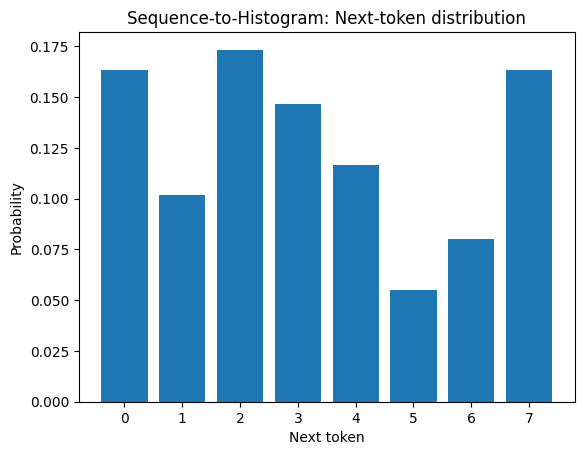

In [21]:
# Visualise the predicted next-token histogram

probabilities = histogram_model.predict([])

plt.bar(range(8), probabilities)
plt.xlabel('Next token')
plt.ylabel('Probability')
plt.title('Sequence-to-Histogram: Next-token distribution')
plt.xticks(range(8))
plt.show()

In [22]:
# Save the histograms
import pickle

with open(os.path.join(SAVE_DIR, 'sequence_to_histogram.pkl'), 'wb') as f:
    pickle.dump(dict(histogram_model.histograms), f)

print('Histogram model saved!')

Histogram model saved!
